In [1]:
import os
import random
import gc

import torch
import torchvision
import torchvision.datasets as datasets
import torch.nn as nn
import torch.optim as optim
import torch.nn.functional as F

from sklearn.preprocessing import LabelEncoder
from sklearn.model_selection import KFold, train_test_split
from sklearn.cluster import KMeans

import cv2
from imutils import paths
import numpy as np
import scipy.io
import matplotlib.pyplot as plt
%matplotlib inline

In [2]:
os.sys.path.append('../src')
from helpers import resize_to_fit

# Load dataset

In [3]:
data_dir = os.path.abspath(os.path.relpath('../data'))
image_dir = os.path.abspath(os.path.relpath('../doc/images'))

In [4]:
CAPTCHA_IMAGES_FOLDER = "../data/samples"

# initialize the data and labels
data = []
labels = []

# loop over the input images
for image_file in paths.list_images(CAPTCHA_IMAGES_FOLDER):
    # Load the image and convert it to grayscale
    image = cv2.imread(image_file)
    image = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)

    # Grab the labels
    label = image_file.split(os.path.sep)[-1].split('.')[-2]

    # Add the image and it's label to our training data
    data.append(image)
    labels.append(label)

In [5]:
data_pre = []
for e in data:
    ret, th = cv2.threshold(e, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)
    kernel = np.ones((3,3), np.uint8)
    dilation = cv2.dilate(th, kernel, iterations=1)
    erosion = cv2.erode(dilation, kernel, iterations=1)

    data_pre.append(erosion)

In [6]:
data_pts = []
for e in data_pre:
    data_pts.append(np.where(e == 0))
data_pts = np.array(data_pts)
data_pts.shape

(1070, 2)

In [7]:
X = []
thres = 7
for e in data_pts:
    x = (np.vstack((e[1],np.flip(e[0])))).T
    l = []
    # Discard columns with less than thres points
    for i in range(200):
        if len(x[x[:,0] == i]) > thres:
            for f in x[x[:,0] == i]:
                l.append(f)
    x = np.array(l)
    X.append(x)
X = np.array(X)
X.shape

(1070,)

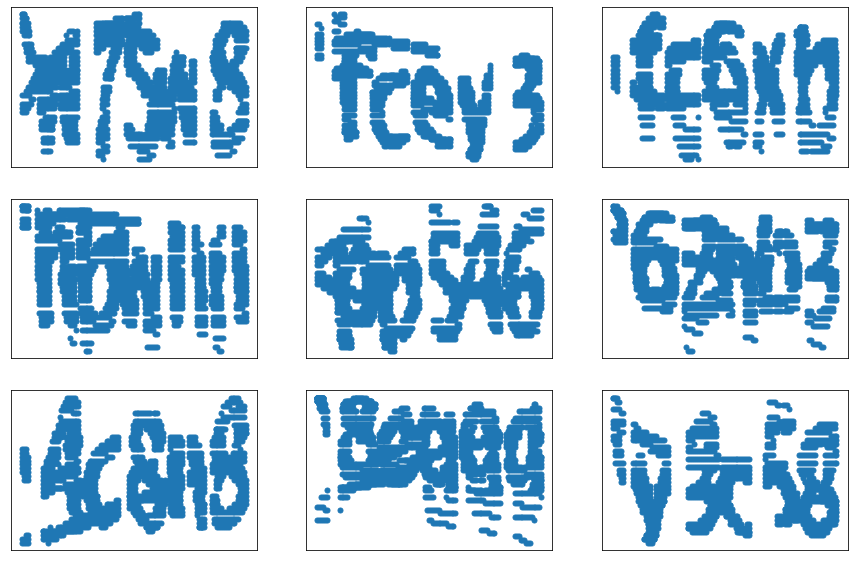

In [8]:
# Show points
fig = plt.figure(figsize=(15, 10))
for i in range(9):
    plt.subplot(3,3,i+1)
    plt.scatter(X[i][:,0], X[i][:,1], s=100, marker='.')
    plt.xticks([])
    plt.yticks([])

In [9]:
# Projection in x-axis
X_proj = [x[:,0].reshape(-1,1) for x in X]

In [10]:
# Find clusters in projected data
y_kmeans_proj = []
centers_kmeans_proj = []
for i, x in enumerate(X_proj):
    kmeans = KMeans(n_clusters=5)#, init=np.array([(i*200/6.0, 25) for i in range(1,6)]))
    kmeans.fit(x)
    centers_kmeans_proj.append(kmeans.cluster_centers_)
    y_kmeans_proj.append(kmeans.predict(x))

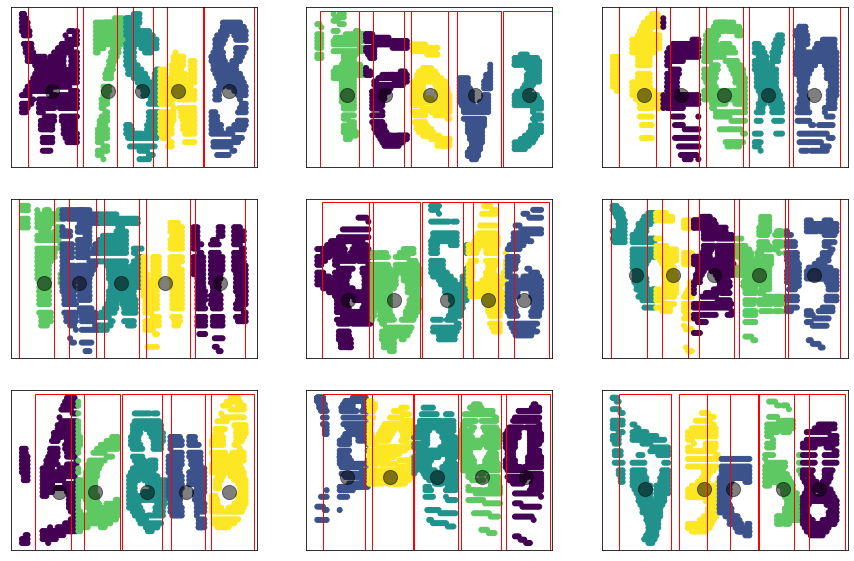

In [11]:
# Show clusters
from matplotlib.patches import Rectangle
fig = plt.figure(figsize=(15, 10))
for i in range(9):
    plt.subplot(3,3,i+1)
    plt.scatter(X[i][:, 0], X[i][:, 1], c=y_kmeans_proj[i], s=100, cmap='viridis', marker='.')
    centers = centers_kmeans_proj[i]
    plt.scatter(centers, np.ones(centers.shape)*25, c='black', s=200, alpha=0.5, marker='o')
    plt.xticks([])
    plt.yticks([])
    currentAxis = plt.gca()
    for c in centers:
        currentAxis.add_patch(Rectangle((c - 13, 0), 26, 50, color="red", fill=False))
plt.show()

# Crop and save images

In [12]:
centers = [np.sort(e, axis=0) for e in centers_kmeans_proj]

In [13]:
size_crops = [10, 12, 14, 16, 18, 19, 20, 21, 22]
size_crops

[10, 12, 14, 16, 18, 19, 20, 21, 22]

In [14]:
for sze_crp in size_crops:
    data_chars = []
    size_str = str(sze_crp)
    for i, e in enumerate(data_pre):
        chars = []
        for j in range(5):
            chars.append(e[:,int(centers[i][j]-sze_crp):int(centers[i][j]+sze_crp)])
        data_chars.append(chars)

    letters_dir = os.path.join(data_dir, 'letters_tst_size/')
    letters_dir = '../data/letters_tst_size/'

    if not(os.path.isdir(''.join((letters_dir,size_str)))):
        os.mkdir(''.join((letters_dir,size_str)))

    for i,e in enumerate(data_chars):
        for j in range(5):
            if not(os.path.isdir(''.join((letters_dir,'/',size_str,'/',labels[i][j],'/')))):
                os.mkdir(''.join((letters_dir,'/',size_str,'/',labels[i][j],'/')))
            cv2.imwrite(''.join((letters_dir,'/',size_str,'/',labels[i][j],'/',str(i),'.png')),e[j])

## Convolutional Neural Network

In [15]:
for sze_crp in size_crops:
    
    LETTER_IMAGES_FOLDER = ''.join((letters_dir,'/',str(sze_crp),'/'))

    # initialize the data and labels
    data = []
    labels = []

    # loop over the input images
    for image_file in paths.list_images(LETTER_IMAGES_FOLDER):
        # Load the image and convert it to grayscale
        image = cv2.imread(image_file)
        image = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)

        # Resize the letter so it fits in a 28x28 pixel box
        image = resize_to_fit(image, 28, 28)

        # Add a third channel dimension to the image to make Keras happy
        image = np.expand_dims(image, axis=2)

        # Grab the name of the letter based on the folder it was in
        label = image_file.split(os.path.sep)[-2]

        # Add the letter image and it's label to our training data
        data.append(image)
        labels.append(label)


    # scale the raw pixel intensities to the range [0, 1] (this improves training)
    data = np.array(data, dtype="float") / 255.0
    labels = np.array(labels)

    # Split the training data into separate train and test sets
    (X_train, X_test, y_train, y_test) = train_test_split(data, labels, test_size=0.25, random_state=0)

    # Convert the labels (letters) into one-hot encodings that Keras can work with
    le = LabelEncoder().fit(y_train)
    y_train = le.transform(y_train)
    y_test = le.transform(y_test)

    batch_size_train = 100
    batch_size_test = 1000
    learning_rate = 0.01
    n_epochs = 10
    log_interval = 10

    X_train_t = (torch.from_numpy(X_train).float().transpose(1,3)).transpose(2,3)
    y_train_t = torch.from_numpy(y_train).long()

    train_data = torch.utils.data.TensorDataset(X_train_t, y_train_t)
    train_loader = torch.utils.data.DataLoader(train_data, batch_size=round(batch_size_train), shuffle=True)
    
    X_test_t = (torch.from_numpy(X_test).float().transpose(1,3)).transpose(2,3)
    y_test_t = torch.from_numpy(y_test).long()

    test_data = torch.utils.data.TensorDataset(X_test_t, y_test_t)
    test_loader = torch.utils.data.DataLoader(test_data, batch_size=batch_size_test, shuffle=True)
    
    examples = enumerate(test_loader)
    batch_idx, (example_data, example_targets) = next(examples)


    class Net(nn.Module):
        def __init__(self):
            super(Net, self).__init__()
            self.conv1 = nn.Conv2d(1, 10, kernel_size=5)
            self.conv2 = nn.Conv2d(10, 20, kernel_size=5)
            self.fc1 = nn.Linear(320, 120)
            self.fc2 = nn.Linear(120, 19)
            self.dropout = nn.Dropout(0.3)

        def forward(self, x):
            x = F.relu(F.max_pool2d(self.conv1(x), 2))
            x = F.relu(F.max_pool2d(self.conv2(x), 2))
            x = x.view(-1, 320)
            x = F.relu(self.fc1(x))
            x = self.dropout(x)
            x = self.fc2(x)
            x = self.dropout(x)
            return F.log_softmax(x, dim=0)

    net = Net()
    optimizer = optim.Adam(net.parameters(), lr=learning_rate)

    train_losses = []
    train_counter = []
    test_losses = []
    test_counter = [i*len(train_loader.dataset) for i in range(n_epochs + 1)]

    def train(epoch, v=True):
        net.train()
        for batch_idx, (data, target) in enumerate(train_loader):
            optimizer.zero_grad()
            output = net(data)
            loss = F.nll_loss(output, target, reduction='mean')
            loss.backward()
            optimizer.step()
            if batch_idx % log_interval == 0:
#                 if v:
#                     print('Train Epoch: {} [{}/{} ({:.0f}%)]\tLoss: {:.6f}'.format(
#                     epoch, batch_idx * len(data), len(train_loader.dataset),
#                     100. * batch_idx / len(train_loader), loss.item()))
                train_losses.append(loss.item())
                train_counter.append(
                (batch_idx*64) + ((epoch-1)*len(train_loader.dataset)))
            torch.save(net.state_dict(), 'model.pth')
            torch.save(optimizer.state_dict(), 'optimizer.pth')

    def test(final_flag):
        net.eval()
        test_loss = 0
        correct = 0
        with torch.no_grad():
            for data, target in test_loader:
                output = net(data)
                test_loss += F.nll_loss(output, target, reduction='sum').item()
                pred = output.data.max(1, keepdim=True)[1]
                correct += pred.eq(target.data.view_as(pred)).sum()
        test_loss /= len(test_loader.dataset)
        test_losses.append(test_loss)
        if final_flag==1:
            print('\nTest set: Avg. loss: {:.4f}, Accuracy: {}/{} ({:.0f}%)\n'.format(
            test_loss, correct, len(test_loader.dataset),
            100. * correct / len(test_loader.dataset)))

#     test()
    for epoch in range(1, n_epochs + 1):
        train(epoch)
        if epoch==n_epochs:
            print("\nCrop Size: {} \n".format(sze_crp))
            test(1)
        else:
            test(0)



Crop Size: 10 


Test set: Avg. loss: 4.2866, Accuracy: 1056/1199 (88%)


Crop Size: 12 


Test set: Avg. loss: 4.2740, Accuracy: 1055/1199 (87%)


Crop Size: 14 


Test set: Avg. loss: 4.2186, Accuracy: 1084/1199 (90%)


Crop Size: 16 


Test set: Avg. loss: 4.3523, Accuracy: 1069/1199 (89%)


Crop Size: 18 


Test set: Avg. loss: 4.1854, Accuracy: 1103/1199 (91%)


Crop Size: 19 


Test set: Avg. loss: 4.0999, Accuracy: 2019/2109 (95%)


Crop Size: 20 


Test set: Avg. loss: 4.0964, Accuracy: 1128/1199 (94%)


Crop Size: 21 


Test set: Avg. loss: 4.0911, Accuracy: 2031/2109 (96%)



error: OpenCV(4.1.0) /io/opencv/modules/imgproc/src/color.cpp:182: error: (-215:Assertion failed) !_src.empty() in function 'cvtColor'
